# T06 — Chuyển đổi Module 3: CNN + LSTM (MNIST Summation)

Notebook này chuyển đổi mô hình **CNN + LSTM** tính tổng chuỗi chữ số viết tay MNIST từ Keras (`examples/3. CNN + LSTM/MNIST_CNN_LSTM.ipynb`) sang PyTorch.

## Tóm tắt thiết kế chuyển đổi từ `examples`
- **Tiền xử lý dữ liệu (`src/lstm_dataset.py`):**
  - Ảnh MNIST `28x28` được scale về `float32` trong `[0, 1]` (giống `/ 255.0` của Keras, **không** dùng `Normalize(mean, std)` để các bước thời gian đệm `0` giữ nguyên giá trị `0.0`).
  - Chia stratified 90% train / 10% validation từ 60,000 ảnh gốc trước khi sinh chuỗi (tương tự `src/train_cnn.py`), giữ nguyên 10,000 ảnh test độc lập để tránh rò rỉ dữ liệu.
  - Mỗi mẫu chọn ngẫu nhiên `1..max_to_add` ảnh (`max_to_add=8` theo code Keras gốc; kiến trúc cũng hỗ trợ trực tiếp chuỗi `7` ảnh như mô tả trên Task Tracking), đệm `0` ở các bước còn lại và lấy tổng nhãn làm target.
- **Kiến trúc mạng (`src/lstm_models.py`):**
  - Thân CNN 3 khối (`64 -> 128 -> 256`, mỗi khối gồm `Conv2d(3x3, padding=1) -> ReLU -> MaxPool2d(2) -> Dropout(0.2)`) tái sử dụng thiết kế từ `1_MNIST_CNN.ipynb` và `MNIST_CNN_LSTM.ipynb`, áp dụng cho từng bước thời gian theo cơ chế tương đương `TimeDistributed` (`[B, T, 1, 28, 28] -> [B*T, 1, 28, 28] -> [B, T, 2304]`).
  - Đầu chuỗi gồm 2 tầng `nn.LSTM(hidden_size=128, batch_first=True)` (`return_sequences=True` rồi lấy bước cuối `[:, -1, :]`), `Dropout(0.22)` và `nn.Linear(128, 1)`.
  - Khởi tạo trọng số theo mặc định Keras (`xavier_uniform_` cho Conv/Linear/LSTM `ih`, `orthogonal_` cho LSTM `hh`, `unit_forget_bias=1.0`).
- **Hàm mất mát & tiện ích huấn luyện (`src/train_lstm.py`):**
  - Dùng `nn.L1Loss()` (MAE) thay cho `'mean_absolute_error'`.
  - Áp dụng lưu best checkpoint theo `val_loss` (`best.pth`, kế thừa `ModelCheckpoint` trong `examples/4. Training Utilities`), hỗ trợ `EarlyStopping` và `ReduceLROnPlateau` qua tham số.

In [1]:
import csv
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "train_lstm.py").is_file():
    raise RuntimeError("Mở notebook từ thư mục BTL03_Keras_to_PyTorch hoặc notebooks/")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.chdir(root)

from src.lstm_dataset import make_mnist_summation_splits
from src.lstm_models import MnistCnnLstm, count_parameters
from src.train_lstm import run_epoch, train_lstm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root : {root}")
print(f"Device       : {device}", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Project root : C:\Users\Viet\Desktop\DoAnHocSau\BTL03_Keras_to_PyTorch
Device       : cuda NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# Kiểm tra kiến trúc, số tham số và tính tương thích cho chuỗi 7 ảnh và 8 ảnh
probe_model = MnistCnnLstm()
param_info = count_parameters(probe_model)
print(probe_model)
print("Parameter breakdown:", param_info)

for seq_len in (7, 8):
    dummy = torch.zeros(2, seq_len, 1, 28, 28)
    out = probe_model(dummy)
    print(f"Forward shape với T={seq_len}: {tuple(dummy.shape)} -> {tuple(out.shape)}")

# Kiểm tra bộ dữ liệu chuỗi MNIST
train_ds, val_ds, test_ds = make_mnist_summation_splits("data/mnist", max_to_add=8, val_ratio=0.1, split_seed=42, sequence_seed=2018)
sample_seq, sample_sum = train_ds[0]
print(f"Train sequences: {len(train_ds)} | Val sequences: {len(val_ds)} | Test sequences: {len(test_ds)}")
print(f"Sample shape: {tuple(sample_seq.shape)}, dtype={sample_seq.dtype}, range=[{sample_seq.min():.1f}, {sample_seq.max():.1f}], sum={sample_sum.item():.0f}")

MnistCnnLstm(
  (cnn): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.2, inplace=False)
    (12): Flatten(start_dim=1, end_dim=-1)
  )
  (lstm1): LSTM(2304, 128, batch_first=True)
  (lstm2): LSTM(128, 128, batch_first=True)
  (lstm_dropout): Dropout(p=0.22, inplace=False)
  (head): Linear(in_features=128, out_features=1, bias=True)
)
Parameter breakdown: {'pytorch_para

Forward shape với T=8: (2, 8, 1, 28, 28) -> (2, 1)


Train sequences: 54001 | Val sequences: 5999 | Test sequences: 10000
Sample shape: (8, 1, 28, 28), dtype=torch.float32, range=[0.0, 1.0], sum=38


In [3]:
run_dir = Path("results/lstm_summation_seed42")
config = dict(
    data_dir=Path("data/mnist"),
    output_dir=run_dir,
    max_to_add=8,
    val_ratio=0.1,
    epochs=30,
    batch_size=128,
    lr=0.01,
    optimizer_name="sgd",
    seed=42,
    sequence_seed=2018,
)

if not (run_dir / "metrics.json").is_file():
    metrics = train_lstm(**config)
else:
    metrics = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))

print(json.dumps(metrics, indent=2, ensure_ascii=False))

{
  "task": "T06_mnist_cnn_lstm",
  "loss_function": "L1Loss (MAE)",
  "max_to_add": 8,
  "min_to_add": 1,
  "val_ratio": 0.1,
  "seed": 42,
  "sequence_seed": 2018,
  "keras_init": true,
  "device": "cuda",
  "device_name": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "batch_size": 128,
  "initial_lr": 0.01,
  "optimizer": "sgd",
  "momentum": 0.0,
  "epochs_requested": 30,
  "epochs_completed": 30,
  "best_epoch": 28,
  "parameters": 1748097,
  "keras_equivalent_parameters": 1747073,
  "train_samples": 54001,
  "validation_samples": 5999,
  "test_samples": 10000,
  "validation": {
    "loss": 0.6079029433626715,
    "rmse": 1.0784211294514245,
    "exact_accuracy": 0.6531088514752459,
    "within_1_accuracy": 0.835639273212202
  },
  "test": {
    "loss": 0.5963868527412415,
    "rmse": 1.060219060444149,
    "exact_accuracy": 0.6637,
    "within_1_accuracy": 0.8393
  },
  "training_seconds": 1131.5363312000409,
  "mean_epoch_seconds": 37.71787770666803
}


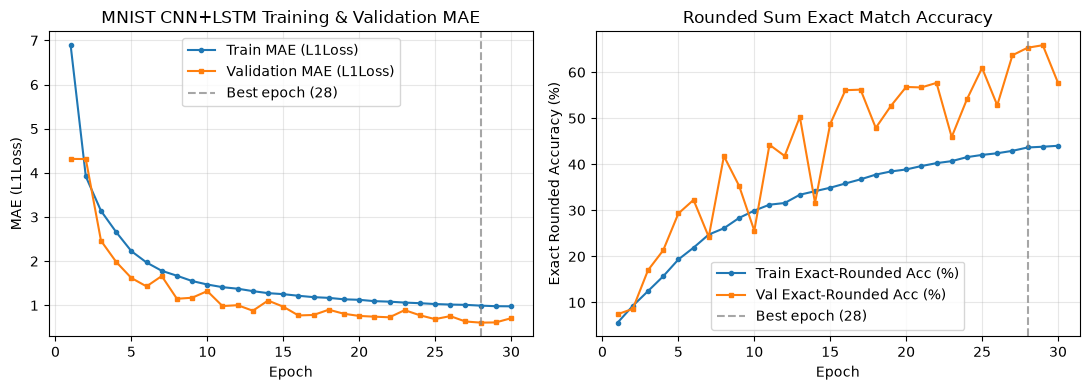

In [4]:
with (run_dir / "history.csv").open(encoding="utf-8") as f:
    history = list(csv.DictReader(f))

epochs_x = [int(r["epoch"]) for r in history]
train_mae = [float(r["train_loss"]) for r in history]
val_mae = [float(r["val_loss"]) for r in history]
train_acc = [float(r["train_exact_accuracy"]) * 100 for r in history]
val_acc = [float(r["val_exact_accuracy"]) * 100 for r in history]
best_ep = metrics["best_epoch"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs_x, train_mae, marker="o", markersize=3, label="Train MAE (L1Loss)")
axes[0].plot(epochs_x, val_mae, marker="s", markersize=3, label="Validation MAE (L1Loss)")
axes[0].axvline(best_ep, color="gray", linestyle="--", alpha=0.7, label=f"Best epoch ({best_ep})")
axes[0].set(xlabel="Epoch", ylabel="MAE (L1Loss)", title="MNIST CNN+LSTM Training & Validation MAE")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_x, train_acc, marker="o", markersize=3, label="Train Exact-Rounded Acc (%)")
axes[1].plot(epochs_x, val_acc, marker="s", markersize=3, label="Val Exact-Rounded Acc (%)")
axes[1].axvline(best_ep, color="gray", linestyle="--", alpha=0.7, label=f"Best epoch ({best_ep})")
axes[1].set(xlabel="Epoch", ylabel="Exact Rounded Accuracy (%)", title="Rounded Sum Exact Match Accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()
plots_dir = Path("results/plots")
plots_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(run_dir / "learning_curve.png", dpi=160)
fig.savefig(plots_dir / "lstm_learning_curve.png", dpi=160)
plt.show()

Test (T=8, max_to_add=8)            : {'loss': 0.5963868527412415, 'rmse': 1.060219060444149, 'exact_accuracy': 0.6637, 'within_1_accuracy': 0.8393}
Test (1..7 ảnh, đệm lên T=8)        : {'loss': 0.5241206558227539, 'rmse': 0.9548299378120355, 'exact_accuracy': 0.7088, 'within_1_accuracy': 0.8696}
Test (1..7 ảnh, T=7 không đệm)      : {'loss': 2.507055631637573, 'rmse': 2.817007027987975, 'exact_accuracy': 0.0248, 'within_1_accuracy': 0.1117} (lệch bước cuối do model train với T=8; train riêng dùng max_to_add=7)


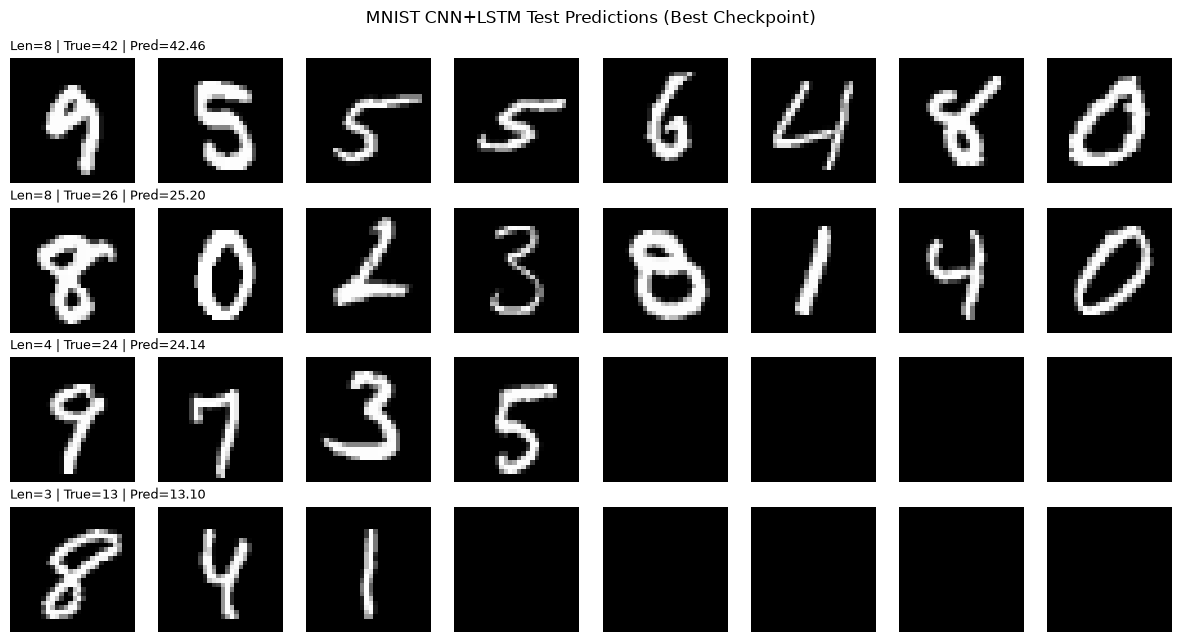

In [5]:
# Nạp lại trọng số tốt nhất để kiểm thử trên tập test độc lập (cả T=8 và T=7)
eval_model = MnistCnnLstm().to(device)
eval_model.load_state_dict(torch.load(run_dir / "best.pth", map_location=device, weights_only=True))
eval_model.eval()

_, _, test_ds_7 = make_mnist_summation_splits("data/mnist", max_to_add=7, val_ratio=0.1, split_seed=42, sequence_seed=2018)
test_loader_7 = torch.utils.data.DataLoader(test_ds_7, batch_size=128, shuffle=False)
test_7_unpadded = run_epoch(eval_model, test_loader_7, device)

# Đệm thêm 1 frame 0 ở cuối để khớp độ dài T=8 khi suy luận chuỗi tối đa 7 ảnh
class _PadToEightLoader:
    def __init__(self, loader):
        self.loader = loader
    def __iter__(self):
        for seq, y in self.loader:
            pad = torch.zeros(seq.size(0), 1, 1, 28, 28, dtype=seq.dtype)
            yield torch.cat([seq, pad], dim=1), y

test_7_padded = run_epoch(eval_model, _PadToEightLoader(test_loader_7), device)
print("Test (T=8, max_to_add=8)            :", metrics["test"])
print("Test (1..7 ảnh, đệm lên T=8)        :", test_7_padded)
print("Test (1..7 ảnh, T=7 không đệm)      :", test_7_unpadded, "(lệch bước cuối do model train với T=8; train riêng dùng max_to_add=7)")

# Trực quan hóa dự đoán ngẫu nhiên trên tập test
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(test_ds), size=4, replace=False)
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))

with torch.no_grad():
    for row_idx, ds_idx in enumerate(sample_indices):
        seq, true_sum = test_ds[int(ds_idx)]
        pred_sum = eval_model(seq.unsqueeze(0).to(device)).item()
        n_digits = int(test_ds.lengths[int(ds_idx)].item())
        for t in range(8):
            ax = axes[row_idx, t]
            ax.imshow(seq[t, 0].numpy(), cmap="gray", vmin=0.0, vmax=1.0)
            ax.axis("off")
            if t == 0:
                ax.set_title(f"Len={n_digits} | True={true_sum.item():.0f} | Pred={pred_sum:.2f}", loc="left", fontsize=9)

fig.suptitle("MNIST CNN+LSTM Test Predictions (Best Checkpoint)", fontsize=12)
fig.tight_layout()
fig.savefig(run_dir / "prediction_samples.png", dpi=160)
fig.savefig(plots_dir / "lstm_prediction_samples.png", dpi=160)
plt.show()